# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import HRPlanesv2Dataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 1490


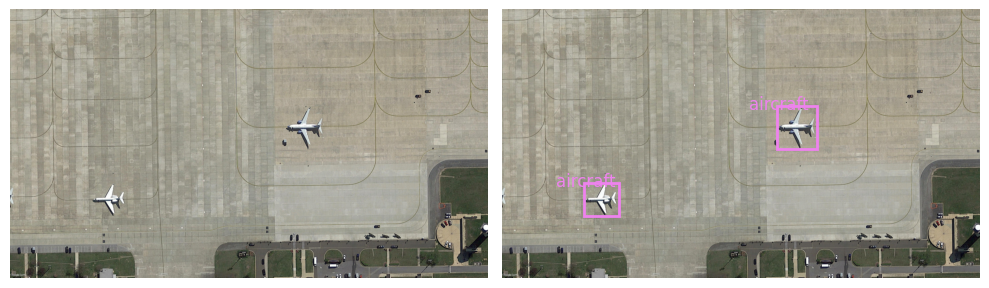

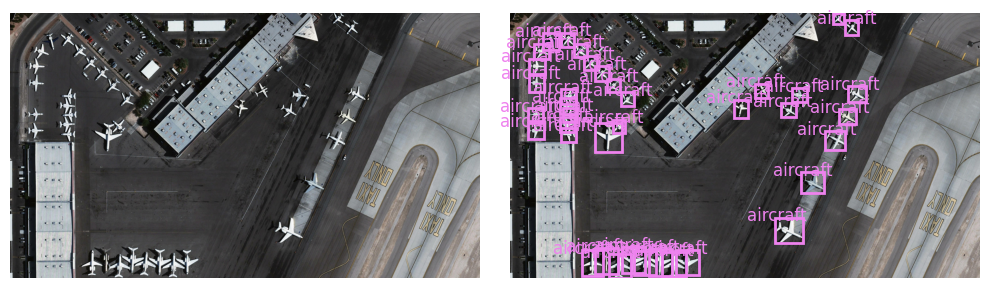

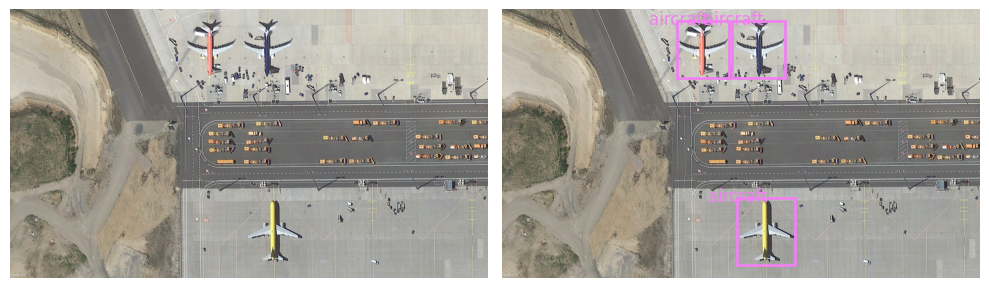

In [16]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/HRPlanesv2/train/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/HRPlanesv2/train/labels/",
}
dataset = HRPlanesv2Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(5);
dataset.show_image(10);
dataset.show_image(100);

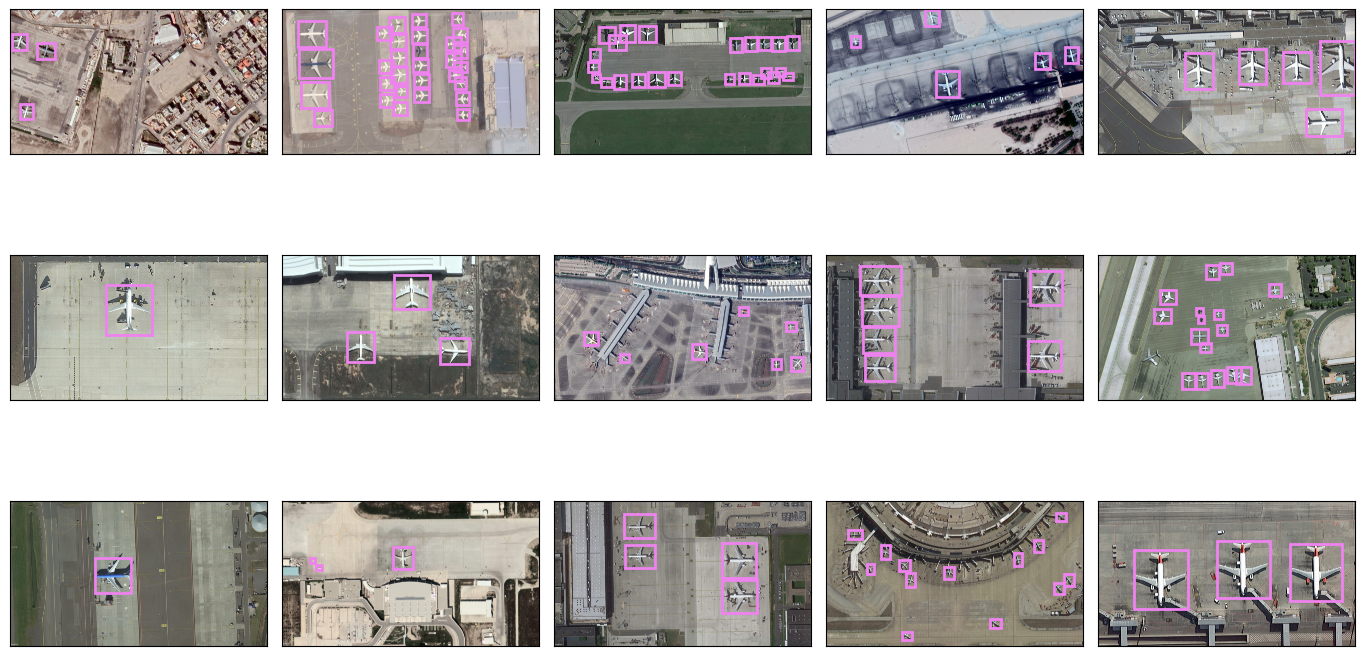

In [17]:
dataset.show_batch(15);

In [18]:
dataset.data_distribution_table()

,Label,Count
0,aircraft,9733


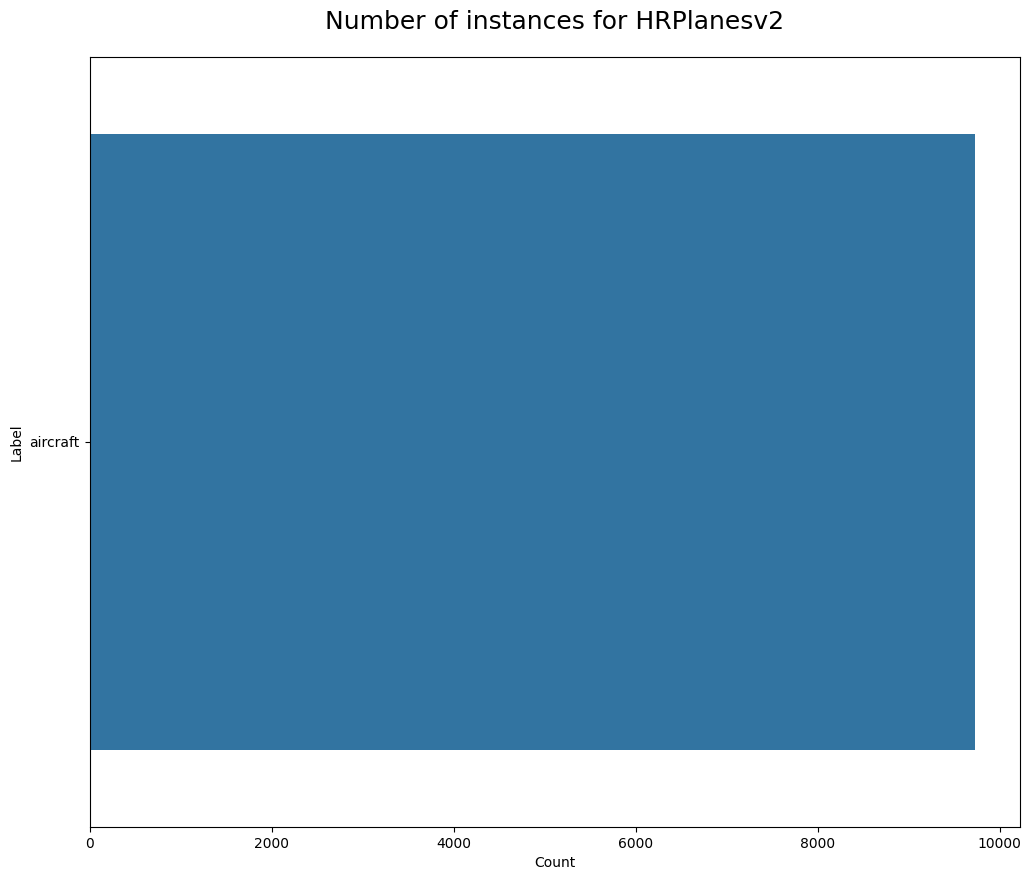

In [19]:
dataset.data_distribution_barchart();

## Load train data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/HRPlanesv2/train/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/HRPlanesv2/train/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = HRPlanesv2Dataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1490


## Create the model

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/HRPlanesv2/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-29 06:46:01,396 INFO Starting training.
training: 100%|██████████| 187/187 [01:11<00:00,  2.62it/s]
2025-05-29 06:47:13,231 INFO epoch: 1, time: 72, loss:  0.23019
testing on train set: 100%|██████████| 187/187 [01:51<00:00,  1.68it/s]
2025-05-29 06:49:11,456 INFO map:0.7622939348220825, map_50:0.9879135489463806, map_75:0.9384407997131348, map_small:0.6885024309158325, map_medium:0.7959862947463989, map_large:0.8528878688812256, mar_1:0.1288502961397171, mar_10:0.6085996031761169, mar_100:0.8083221912384033, mar_small:0.7427214980125427, mar_medium:0.8475193977355957, mar_large:0.8874371647834778, map_per_class:0.7622939348220825, mar_100_per_class:0.8083221912384033, classes:1.0
training: 100%|██████████| 187/187 [01:48<00:00,  1.72it/s]
2025-05-29 06:50:59,955 INFO epoch: 2, time: 108, loss:  0.14033
testing on train set: 100%|██████████| 187/187 [01:35<00:00,  1.96it/s]
2025-05-29 06:52:41,052 INFO map:0.79966801404953, map_50:0.9888138771057129, map_75:0.9651191234588623, 

## Evaluate the model

In [9]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/HRPlanesv2/val/images/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/HRPlanesv2/val/labels/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = HRPlanesv2Dataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/HRPlanesv2/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 420


2025-05-29 07:22:27,995 INFO Loading checkpoint /home/dragik/data/FAIR_EO/HRPlanesv2/experiments/checkpoint.pth.tar
2025-05-29 07:22:28,963 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/HRPlanesv2/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 53/53 [00:42<00:00,  1.24it/s]


[{'map': 0.7594506740570068,
  'map_50': 0.96811842918396,
  'map_75': 0.9410240054130554,
  'map_small': 0.6990966796875,
  'map_medium': 0.8077746033668518,
  'map_large': 0.8412045836448669,
  'mar_1': 0.13872356712818146,
  'mar_10': 0.5853562951087952,
  'mar_100': 0.7996867895126343,
  'mar_small': 0.7467585206031799,
  'mar_medium': 0.8464166522026062,
  'mar_large': 0.8766666650772095,
  'map_per_class': 0.7594506740570068,
  'mar_100_per_class': 0.7996867895126343,
  'classes': 1.0}]

## Predictions

2025-05-29 07:24:23,019 INFO Loading checkpoint /home/dragik/data/FAIR_EO/HRPlanesv2/experiments/checkpoint.pth.tar
2025-05-29 07:24:23,348 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/HRPlanesv2/experiments/checkpoint.pth.tar at epoch 11


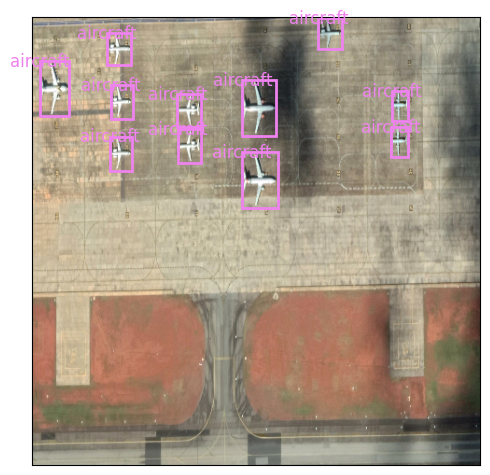

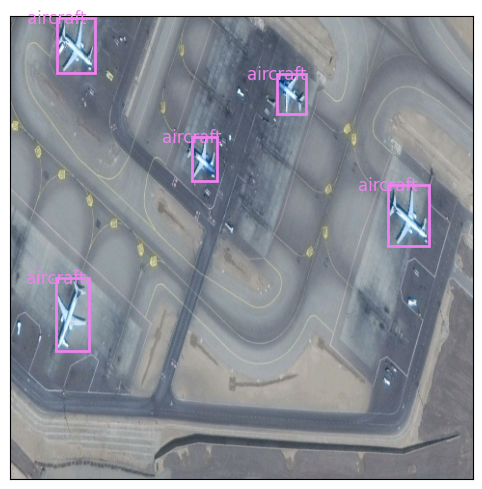

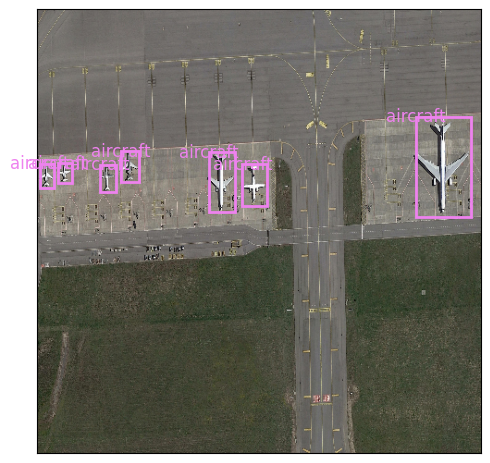

In [10]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/HRPlanesv2/experiments/checkpoint.pth.tar"
labels = ["no-data","aircraft"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/HRPlanesv2/test/images/005_set2.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HRPlanesv2/test/images/017_set2.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/HRPlanesv2/test/images/047_set2.jpg')
fig = model.detect_objects(image, labels, transform)